In [1]:
from anemone.forwards import *
import torch
import matplotlib.pyplot as plt
import numpy as np


class ForwardHankel6(Forward):
    geomz = None
    t2t   = None
    t_eval = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)

    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]            
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                return torch.squeeze(intg)
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Ht, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-6)
            else:
                Ht = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb), self.geomz)
            if self.filterfunc is not None:
                Ht *= self.filterfunc.omega_filter(self.omega)
            if self.waveform is not None:
                Ht /= -1j*self.omega.squeeze()
            return Ht
        cbft=invFourier(frq_integrand, smp_per_decade=16, device=self.device)
        # cbft.preintegrate()
        t,Ht = cbft.range(self.tmin, self.tmax)
        Ht = Ht.real
        if self.t_eval is None:
            self.t_eval = t
        if self.t2t is None:
            self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t)
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()


In [2]:
fwr1 = ForwardHankel6.example()
fwr0 = Forward.example()

/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
rho = torch.tensor([1, 2, 0.5])*40.
thick = torch.ones(2)*30

dbdt1 = fwr1(rho, thick)
dbdt0 = fwr0(rho, thick)

In [5]:
dbdt1 = fwr1(rho, thick)

In [6]:
%%timeit
dbdt = fwr0(rho, thick)

92.6 ms ± 2.91 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [106]:
%%timeit
dbdt = fwr1(rho, thick)

The slowest run took 10.61 times longer than the fastest. This could mean that an intermediate result is being cached.
61.5 ms ± 39.6 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


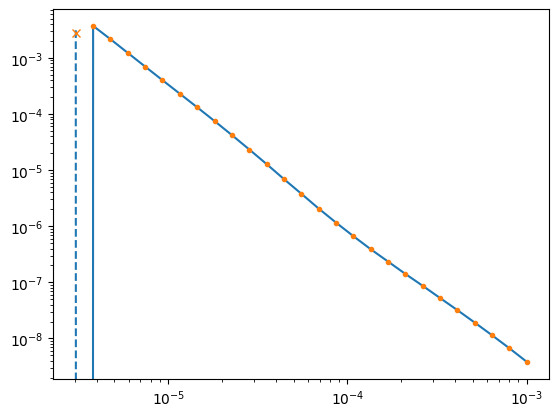

In [7]:
plt.figure()
plt.loglog(fwr1.times, dbdt1)
plt.loglog(fwr1.times,-dbdt1, 'C0--')
plt.loglog(fwr0.times, dbdt0, 'C1.')
plt.loglog(fwr0.times,-dbdt0, 'C1x')